## Unsupervised Learning

K-Means clustering is used to group customer shopping sessions based on similarities in behaviour This is done to find patterns in shopping behaviour without using revenue

The clusters will then be analysed and used as additional features to see whether they improve purchase prediction.

## 1. Import Libraries

In [21]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import silhouette_score, f1_score


## 2. Load Prepared Data

In [22]:
data = joblib.load("data/processed/prepared_data.joblib")

X_train = data["X_train"]
X_test = data["X_test"]
y_train = data["y_train"]
y_test = data["y_test"]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (7818, 31)
Testing data: (1955, 31)


## 3. Find Best Number of clusters

Different number of clusters will be trained on the data and the one with the best silhouette score will be chosen

Clusters: 2 Silhouette score: 0.26652391777008394
Clusters: 3 Silhouette score: 0.2550650787853626
Clusters: 4 Silhouette score: 0.1783785239109492
Clusters: 5 Silhouette score: 0.19387849262339416
Clusters: 6 Silhouette score: 0.18650082726813524


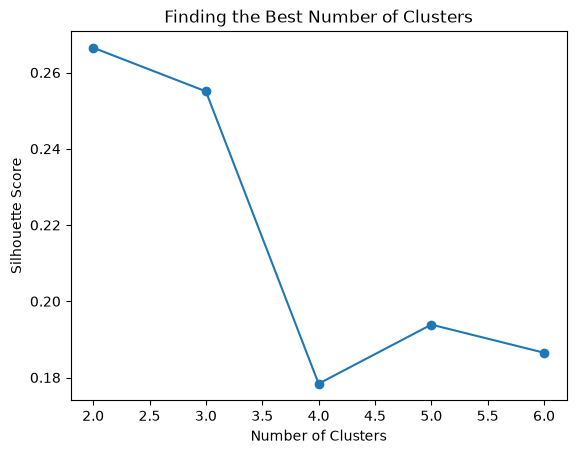

In [23]:
num_clusters = [2, 3, 4, 5, 6]
scores = []

for k in num_clusters:
    kmeans = KMeans(n_clusters=k, random_state=202300408, n_init=10)
    labels = kmeans.fit_predict(X_train)

    score = silhouette_score(X_train, labels, sample_size=1000, random_state=202300408)
    scores.append(score)

    print("Clusters:", k, "Silhouette score:", score)

#plot results
plt.plot(num_clusters, scores, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Finding the Best Number of Clusters")
plt.show()

## 4. Train Final model

In [24]:
best_k = num_clusters[np.argmax(scores)]

kmeans = KMeans(n_clusters=best_k, random_state=202300408, n_init=10)

train_clusters = kmeans.fit_predict(X_train)
test_clusters = kmeans.predict(X_test)

print("Selected number of clusters:", best_k)

Selected number of clusters: 2


## 5. Analyse and Plot Results

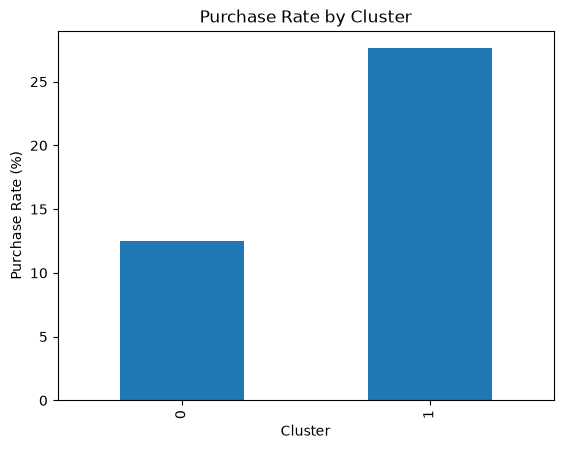

In [25]:
cluster_results = pd.DataFrame({
    "Cluster": train_clusters,
    "Revenue": np.asarray(y_train)
})

cluster_summary = cluster_results.groupby("Cluster")["Revenue"].agg(["count", "mean"])

cluster_summary["Purchase Rate (%)"] = cluster_summary["mean"] * 100

cluster_summary["Purchase Rate (%)"].plot(kind="bar")
plt.xlabel("Cluster")
plt.ylabel("Purchase Rate (%)")
plt.title("Purchase Rate by Cluster")
plt.show()

## 6. Add Cluster info to features

In [26]:
train_distances = kmeans.transform(X_train)
test_distances = kmeans.transform(X_test)

X_train_new = np.hstack([X_train, train_distances])
X_test_new = np.hstack([X_test, test_distances])


## 7. Compare original features to new ones to find best results

In [27]:
#both models have same parameters to have a fair comparison
original_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=202300408
)

cluster_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=202300408
)

original_model.fit(X_train, y_train)
cluster_model.fit(X_train_new, y_train)

original_predictions = original_model.predict(X_test)
cluster_predictions = cluster_model.predict(X_test_new)

original_f1 = f1_score(y_test, original_predictions)
cluster_f1 = f1_score(y_test, cluster_predictions)

print("Original F1:", original_f1)
print("F1 with K-Means features:", cluster_f1)

Original F1: 0.30111524163568776
F1 with K-Means features: 0.300556586270872


## 8. Compare Results

In [28]:
results = pd.DataFrame({
    "Model": ["Random Forest", "Random Forest with K-Means"],
    "F1": [original_f1, cluster_f1]
})

print(results)

joblib.dump(kmeans, "data/processed/kmeans_model.joblib")

                        Model        F1
0               Random Forest  0.301115
1  Random Forest with K-Means  0.300557


['data/processed/kmeans_model.joblib']